# Model Comparison Study: 3D U-Net vs 3D Attention U-Net
## Brain Tumor Segmentation (BraTS2021)

This notebook provides a comprehensive comparison between two 3D models that expect volumetric input of shape (112, 112, 112, 4)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
import nibabel as nib
from pathlib import Path
import time
from scipy.ndimage import distance_transform_edt
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

TensorFlow version: 2.20.0
GPU Available: []


## 1. Load Models

In [2]:
model_paths = {
    'U-Net': r'E:\Radiomics\best_unet_model.keras',
    'Attention U-Net': r'E:\Radiomics\attention\attention_model.keras'
}

models = {}
for name, path in model_paths.items():
    try:
        models[name] = keras.models.load_model(path, compile=False)
        print(f"✓ Loaded {name} successfully")
        print(f"  Input shape: {models[name].input_shape}")
        print(f"  Output shape: {models[name].output_shape}")
    except Exception as e:
        print(f"✗ Error loading {name}: {e}")

for name, model in models.items():
    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

✓ Loaded U-Net successfully
  Input shape: (None, 112, 112, 112, 4)
  Output shape: (None, 112, 112, 112, 4)
✓ Loaded Attention U-Net successfully
  Input shape: (None, 112, 112, 112, 4)
  Output shape: (None, 112, 112, 112, 4)


## 2. Model Architecture Comparison


=== Model Architecture Comparison ===
          Model Total Parameters Trainable Parameters  Layers              Input Shape             Output Shape
          U-Net       25,897,316           25,891,428      72 (None, 112, 112, 112, 4) (None, 112, 112, 112, 4)
Attention U-Net       22,765,320           22,759,432     100 (None, 112, 112, 112, 4) (None, 112, 112, 112, 4)


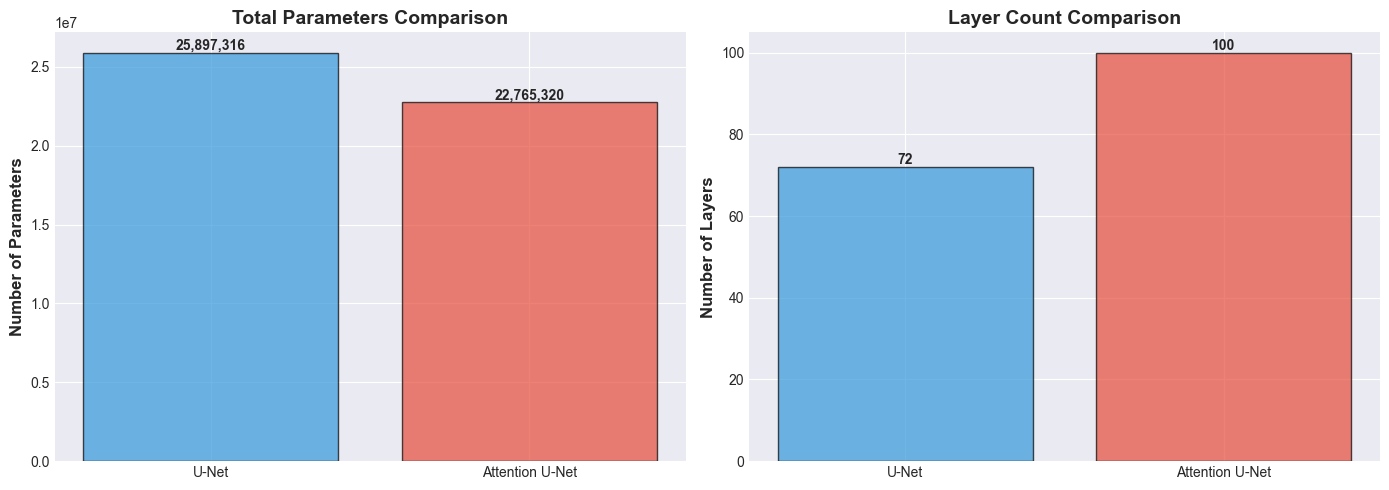

In [3]:
architecture_comparison = []

for name, model in models.items():
    total_params = model.count_params()
    trainable_params = sum([tf.size(w).numpy() for w in model.trainable_weights])
    
    architecture_comparison.append({
        'Model': name,
        'Total Parameters': f"{total_params:,}",
        'Trainable Parameters': f"{trainable_params:,}",
        'Layers': len(model.layers),
        'Input Shape': str(model.input_shape),
        'Output Shape': str(model.output_shape)
    })

arch_df = pd.DataFrame(architecture_comparison)
print("\n=== Model Architecture Comparison ===")
print(arch_df.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
param_data = [model.count_params() for model in models.values()]
colors = ['#3498db', '#e74c3c']

ax[0].bar(models.keys(), param_data, color=colors, alpha=0.7, edgecolor='black')
ax[0].set_ylabel('Number of Parameters', fontsize=12, fontweight='bold')
ax[0].set_title('Total Parameters Comparison', fontsize=14, fontweight='bold')
for i, v in enumerate(param_data):
    ax[0].text(i, v, f"{v:,}", ha='center', va='bottom', fontweight='bold')

layer_data = [len(model.layers) for model in models.values()]
ax[1].bar(models.keys(), layer_data, color=colors, alpha=0.7, edgecolor='black')
ax[1].set_ylabel('Number of Layers', fontsize=12, fontweight='bold')
ax[1].set_title('Layer Count Comparison', fontsize=14, fontweight='bold')
for i, v in enumerate(layer_data):
    ax[1].text(i, v, str(v), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('model_architecture_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## 3. Load and Preprocess Test Data

In [4]:
# Get expected input size from model
model_input_shape = list(models.values())[0].input_shape
TARGET_SIZE = model_input_shape[1]  # Should be 112
print(f"Target volume size: {TARGET_SIZE}x{TARGET_SIZE}x{TARGET_SIZE}")

data_dir = Path(r'E:\Radiomics\data')
sample_folders = sorted([f for f in data_dir.iterdir() if f.is_dir()])[:20]

def crop_or_pad_volume(volume, target_size):
    """Crop or pad volume to target size"""
    current_shape = volume.shape[:3]
    result = volume.copy()
    
    for i in range(3):
        if current_shape[i] > target_size:
            # Crop from center
            start = (current_shape[i] - target_size) // 2
            end = start + target_size
            if i == 0:
                result = result[start:end, :, :, ...]
            elif i == 1:
                result = result[:, start:end, :, ...]
            else:
                result = result[:, :, start:end, ...]
        elif current_shape[i] < target_size:
            # Pad
            pad_before = (target_size - current_shape[i]) // 2
            pad_after = target_size - current_shape[i] - pad_before
            if i == 0:
                result = np.pad(result, ((pad_before, pad_after), (0, 0), (0, 0), (0, 0)), mode='constant')
            elif i == 1:
                result = np.pad(result, ((0, 0), (pad_before, pad_after), (0, 0), (0, 0)), mode='constant')
            else:
                result = np.pad(result, ((0, 0), (0, 0), (pad_before, pad_after), (0, 0)), mode='constant')
    
    return result

def load_sample(folder_path, target_size=112):
    """Load and preprocess a single 3D volume"""
    sample_id = folder_path.name
    
    flair = nib.load(folder_path / f"{sample_id}_flair.nii.gz").get_fdata()
    t1 = nib.load(folder_path / f"{sample_id}_t1.nii.gz").get_fdata()
    t1ce = nib.load(folder_path / f"{sample_id}_t1ce.nii.gz").get_fdata()
    t2 = nib.load(folder_path / f"{sample_id}_t2.nii.gz").get_fdata()
    seg = nib.load(folder_path / f"{sample_id}_seg.nii.gz").get_fdata()
    
    # Stack modalities
    image = np.stack([flair, t1, t1ce, t2], axis=-1)
    
    # Normalize each channel
    for i in range(4):
        img_channel = image[..., i]
        if img_channel.max() > 0:
            image[..., i] = (img_channel - img_channel.mean()) / (img_channel.std() + 1e-8)
    
    # Resize to target dimensions
    image = crop_or_pad_volume(image, target_size)
    seg_expanded = np.expand_dims(seg, axis=-1)
    seg_processed = crop_or_pad_volume(seg_expanded, target_size)
    seg = seg_processed[..., 0]
    
    return image, seg, sample_id

print("Loading test data...")
test_images = []
test_masks = []
sample_ids = []

for folder in sample_folders[:10]:  # First 10 samples
    img, mask, sid = load_sample(folder, target_size=TARGET_SIZE)
    test_images.append(img)
    test_masks.append(mask)
    sample_ids.append(sid)
    print(f"  Loaded {sid}: shape {img.shape}")

print(f"\nLoaded {len(test_images)} test samples")
print(f"Image shape: {test_images[0].shape}")
print(f"Mask shape: {test_masks[0].shape}")

Target volume size: 112x112x112
Loading test data...
  Loaded BraTS2021_00000: shape (112, 112, 112, 4)
  Loaded BraTS2021_00002: shape (112, 112, 112, 4)
  Loaded BraTS2021_00003: shape (112, 112, 112, 4)
  Loaded BraTS2021_00005: shape (112, 112, 112, 4)
  Loaded BraTS2021_00006: shape (112, 112, 112, 4)
  Loaded BraTS2021_00008: shape (112, 112, 112, 4)
  Loaded BraTS2021_00009: shape (112, 112, 112, 4)
  Loaded BraTS2021_00011: shape (112, 112, 112, 4)
  Loaded BraTS2021_00012: shape (112, 112, 112, 4)
  Loaded BraTS2021_00014: shape (112, 112, 112, 4)

Loaded 10 test samples
Image shape: (112, 112, 112, 4)
Mask shape: (112, 112, 112)


## 4. Define Evaluation Metrics

In [5]:
def dice_coefficient(y_true, y_pred, smooth=1e-6):
    intersection = np.sum(y_true * y_pred)
    return (2. * intersection + smooth) / (np.sum(y_true) + np.sum(y_pred) + smooth)

def iou_score(y_true, y_pred, smooth=1e-6):
    intersection = np.sum(y_true * y_pred)
    union = np.sum(y_true) + np.sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)

def sensitivity_specificity(y_true, y_pred):
    y_true_flat = y_true.flatten()
    y_pred_flat = y_pred.flatten()
    
    tp = np.sum((y_true_flat == 1) & (y_pred_flat == 1))
    tn = np.sum((y_true_flat == 0) & (y_pred_flat == 0))
    fp = np.sum((y_true_flat == 0) & (y_pred_flat == 1))
    fn = np.sum((y_true_flat == 1) & (y_pred_flat == 0))
    
    sensitivity = tp / (tp + fn + 1e-6)
    specificity = tn / (tn + fp + 1e-6)
    
    return sensitivity, specificity

def precision_recall_f1(y_true, y_pred):
    y_true_flat = y_true.flatten()
    y_pred_flat = y_pred.flatten()
    
    tp = np.sum((y_true_flat == 1) & (y_pred_flat == 1))
    fp = np.sum((y_true_flat == 0) & (y_pred_flat == 1))
    fn = np.sum((y_true_flat == 1) & (y_pred_flat == 0))
    
    precision = tp / (tp + fp + 1e-6)
    recall = tp / (tp + fn + 1e-6)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-6)
    
    return precision, recall, f1

def hausdorff_distance_95(y_true, y_pred):
    if np.sum(y_true) == 0 or np.sum(y_pred) == 0:
        return np.nan
    
    dt_true = distance_transform_edt(1 - y_true)
    dt_pred = distance_transform_edt(1 - y_pred)
    
    surface_true = (dt_true == 1)
    surface_pred = (dt_pred == 1)
    
    if np.sum(surface_true) == 0 or np.sum(surface_pred) == 0:
        return np.nan
    
    distances_true_to_pred = dt_pred[surface_true]
    distances_pred_to_true = dt_true[surface_pred]
    all_distances = np.concatenate([distances_true_to_pred, distances_pred_to_true])
    
    return np.percentile(all_distances, 95)

print("Metric functions defined!")

Metric functions defined!


## 5. Evaluate Models on 3D Volumes

In [6]:
tumor_classes = {
    0: 'Background',
    1: 'Necrotic Core (NCR)',
    2: 'Edema',
    3: 'Enhancing Tumor (ET)'
}

results = {name: [] for name in models.keys()}
inference_times = {name: [] for name in models.keys()}

print("Evaluating models on 3D volumes...\n")

for idx, (img, mask) in enumerate(zip(test_images, test_masks)):
    print(f"Processing sample {idx+1}/{len(test_images)}: {sample_ids[idx]}")
    
    for model_name, model in models.items():
        # Measure inference time
        start_time = time.time()
        
        # Predict on 3D volume (add batch dimension)
        img_batch = np.expand_dims(img, axis=0)  # Shape: (1, 112, 112, 112, 4)
        pred = model.predict(img_batch, verbose=0)
        pred_volume = np.argmax(pred[0], axis=-1)  # Shape: (112, 112, 112)
        
        inference_time = time.time() - start_time
        inference_times[model_name].append(inference_time)
        
        # Calculate metrics for each class
        sample_metrics = {'sample_id': sample_ids[idx], 'inference_time': inference_time}
        
        for class_id, class_name in tumor_classes.items():
            y_true_class = (mask == class_id).astype(np.float32)
            y_pred_class = (pred_volume == class_id).astype(np.float32)
            
            dice = dice_coefficient(y_true_class, y_pred_class)
            iou = iou_score(y_true_class, y_pred_class)
            precision, recall, f1 = precision_recall_f1(y_true_class, y_pred_class)
            sensitivity, specificity = sensitivity_specificity(y_true_class, y_pred_class)
            
            if class_id > 0:
                hd95 = hausdorff_distance_95(y_true_class, y_pred_class)
            else:
                hd95 = np.nan
            
            sample_metrics.update({
                f'{class_name}_dice': dice,
                f'{class_name}_iou': iou,
                f'{class_name}_precision': precision,
                f'{class_name}_recall': recall,
                f'{class_name}_f1': f1,
                f'{class_name}_sensitivity': sensitivity,
                f'{class_name}_specificity': specificity,
                f'{class_name}_hd95': hd95
            })
        
        results[model_name].append(sample_metrics)
        print(f"  {model_name}: Time = {inference_time:.2f}s, Mean Dice = {np.mean([sample_metrics[f'{c}_dice'] for c in tumor_classes.values() if c != 'Background']):.4f}")

print("\n✓ Evaluation completed!")

Evaluating models on 3D volumes...

Processing sample 1/10: BraTS2021_00000
  U-Net: Time = 20.00s, Mean Dice = 0.0016
  Attention U-Net: Time = 12.10s, Mean Dice = 0.0271
Processing sample 2/10: BraTS2021_00002
  U-Net: Time = 9.73s, Mean Dice = 0.0900
  Attention U-Net: Time = 10.55s, Mean Dice = 0.0004
Processing sample 3/10: BraTS2021_00003
  U-Net: Time = 9.22s, Mean Dice = 0.0891
  Attention U-Net: Time = 9.41s, Mean Dice = 0.0024
Processing sample 4/10: BraTS2021_00005
  U-Net: Time = 11.05s, Mean Dice = 0.0800
  Attention U-Net: Time = 12.48s, Mean Dice = 0.1713
Processing sample 5/10: BraTS2021_00006
  U-Net: Time = 21.43s, Mean Dice = 0.0966
  Attention U-Net: Time = 21.60s, Mean Dice = 0.0840
Processing sample 6/10: BraTS2021_00008
  U-Net: Time = 21.26s, Mean Dice = 0.0313
  Attention U-Net: Time = 13.63s, Mean Dice = 0.0006
Processing sample 7/10: BraTS2021_00009
  U-Net: Time = 12.17s, Mean Dice = 0.0000
  Attention U-Net: Time = 8.92s, Mean Dice = 0.0015
Processing sampl

## 6. Results Summary and Visualization

In [7]:
results_dfs = {name: pd.DataFrame(data) for name, data in results.items()}

print("\n" + "="*80)
print("COMPREHENSIVE MODEL COMPARISON RESULTS")
print("="*80 + "\n")

comparison_summary = []
tumor_classes_only = [c for c in tumor_classes.values() if c != 'Background']

for model_name, df in results_dfs.items():
    print(f"\nModel: {model_name}")
    print("-" * 60)
    
    summary = {'Model': model_name}
    
    mean_time = df['inference_time'].mean()
    summary['Inference Time (s)'] = f"{mean_time:.2f}"
    print(f"Mean Inference Time: {mean_time:.2f}s")
    
    for class_name in tumor_classes_only:
        dice = df[f'{class_name}_dice'].mean()
        iou = df[f'{class_name}_iou'].mean()
        f1 = df[f'{class_name}_f1'].mean()
        hd95 = df[f'{class_name}_hd95'].mean()
        
        print(f"\n{class_name}:")
        print(f"  Dice: {dice:.4f}")
        print(f"  IoU: {iou:.4f}")
        print(f"  F1: {f1:.4f}")
        print(f"  HD95: {hd95:.2f}mm")
        
        summary.update({
            f'{class_name} Dice': f"{dice:.4f}",
            f'{class_name} IoU': f"{iou:.4f}"
        })
    
    mean_dice = np.mean([df[f'{c}_dice'].mean() for c in tumor_classes_only])
    mean_iou = np.mean([df[f'{c}_iou'].mean() for c in tumor_classes_only])
    
    summary['Mean Dice'] = f"{mean_dice:.4f}"
    summary['Mean IoU'] = f"{mean_iou:.4f}"
    
    print(f"\nOverall Mean Dice: {mean_dice:.4f}")
    print(f"Overall Mean IoU: {mean_iou:.4f}")
    
    comparison_summary.append(summary)

comparison_df = pd.DataFrame(comparison_summary)
comparison_df.to_csv('model_comparison_summary.csv', index=False)
print("\n" + "="*80)
print(comparison_df.to_string(index=False))
print("\n✓ Results saved to 'model_comparison_summary.csv'")


COMPREHENSIVE MODEL COMPARISON RESULTS


Model: U-Net
------------------------------------------------------------
Mean Inference Time: 13.16s

Necrotic Core (NCR):
  Dice: 0.0000
  IoU: 0.0000
  F1: 0.0000
  HD95: 91.37mm

Edema:
  Dice: 0.1821
  IoU: 0.1040
  F1: 0.1821
  HD95: 69.74mm

Enhancing Tumor (ET):
  Dice: 0.0000
  IoU: 0.0000
  F1: 0.0000
  HD95: nanmm

Overall Mean Dice: 0.0607
Overall Mean IoU: 0.0347

Model: Attention U-Net
------------------------------------------------------------
Mean Inference Time: 11.65s

Necrotic Core (NCR):
  Dice: 0.1283
  IoU: 0.0807
  F1: 0.1283
  HD95: 84.20mm

Edema:
  Dice: 0.0008
  IoU: 0.0004
  F1: 0.0008
  HD95: 77.28mm

Enhancing Tumor (ET):
  Dice: 0.0000
  IoU: 0.0000
  F1: 0.0000
  HD95: nanmm

Overall Mean Dice: 0.0430
Overall Mean IoU: 0.0270

          Model Inference Time (s) Necrotic Core (NCR) Dice Necrotic Core (NCR) IoU Edema Dice Edema IoU Enhancing Tumor (ET) Dice Enhancing Tumor (ET) IoU Mean Dice Mean IoU
          U-N